## Title :
Exercise: Confidence Intervals for Beta value

## Description :
The goal of this exercise is to create a plot like the one given below for $\beta_0$ and $\beta_1$. 

<img src="../fig/fig2.png" style="width: 500px;">

## Data Description:

## Instructions:

- Follow the steps from the previous exercise to get the lists of beta values.
- Sort the list of beta values in ascending order (from low to high).
- To compute the 95% confidence interval, find the 2.5 percentile and the 97.5 percentile using `np.percentile()`. 
- Use the helper code `plot_simulation()` to visualise the $\beta$ values along with its confidence interval

## Hints: 

$${\widehat {\beta_1 }}={\frac {\sum _{i=1}^{n}(x_{i}-{\bar {x}})(y_{i}-{\bar {y}})}{\sum _{i=1}^{n}(x_{i}-{\bar {x}})^{2}}}$$

$${\widehat {\beta_0 }}={\bar {y}}-{\widehat {\beta_1 }}\,{\bar {x}}$$

<a href="https://docs.scipy.org/doc/numpy-1.15.0/reference/generated/numpy.random.randint.html" target="_blank">np.random.randint()</a>
Returns list of integers as per mentioned size 

<a href="https://pandas.pydata.org/pandas-docs/stable/reference/api/pandas.DataFrame.iloc.html" target="_blank">df.iloc[]</a>
Purely integer-location based indexing for selection by position

<a href="https://matplotlib.org/3.2.2/api/_as_gen/matplotlib.pyplot.hist.html" target="_blank">plt.hist()</a>
Plots a histogram

<a href="https://matplotlib.org/api/_as_gen/matplotlib.pyplot.axvline.html" target="_blank">plt.axvline()</a>
Adds a vertical line across the axes

<a href="https://matplotlib.org/api/_as_gen/matplotlib.pyplot.axhline.html" target="_blank">plt.axhline()</a>
Add a horizontal line across the axes

<a href="https://matplotlib.org/api/_as_gen/matplotlib.pyplot.xlabel.html" target="_blank">plt.xlabel()</a>
Sets the label for the x-axis

<a href="https://matplotlib.org/api/_as_gen/matplotlib.pyplot.ylabel.html" target="_blank">plt.ylabel()</a>
Sets  the label for the y-axis

<a href="https://matplotlib.org/api/_as_gen/matplotlib.pyplot.legend.html" target="_blank">plt.legend()</a>
Place a legend on the axes

<a href="https://numpy.org/doc/stable/reference/generated/numpy.ndarray.sort.html#numpy.ndarray.sort" target="_blank">ndarray.sort()</a>
Returns the sorted ndarray.

<a href="https://numpy.org/doc/stable/reference/generated/numpy.percentile.html" target="_blank">np.percentile(list, q)</a>
Returns the q-th percentile value based on the provided ascending list of values.

**Note:** This exercise is **auto-graded and you can try multiple attempts**.

In [1]:
# Import necessary libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline


### Reading the standard Advertising dataset

In [2]:
# Read the 'Advertising_adj.csv' file
df = pd.read_csv('Advertising_adj.csv')

# Take a quick look at the data
df.head(3)


,tv,sales
0,230.1,465.26
1,44.5,218.95
2,17.2,195.79


In [3]:
# Use the bootstrap function defined in the previous exercise
def bootstrap(df):
    selectionIndex = np.random.randint(len(df), size = len(df))
    new_df = df.iloc[selectionIndex]
    return new_df


In [4]:
# Initialize empty lists to store beta values from 100 bootstraps 
# of the original data
beta0_list, beta1_list = [],[]

# Set the number of bootstraps
numberOfBootstraps = 100

# Loop over the number of bootstraps
for i in range(numberOfBootstraps):
    
    # Call the function bootstrap with the original dataframe
    df_new = bootstrap(df)
    
    # Compute the mean of the predictor i.e. the TV column
    xmean = df_new.tv.mean()

    # Compute the mean of the response i.e. the Sales column
    ymean = df_new.sales.mean()
    
    # Compute beta1 analytical using the equation in the hints
    beta1 = (((df_new.tv - xmean)*(df_new.sales - ymean)).sum())/(((df_new.tv - xmean)**2).sum())

    # Compute beta1 analytical using the equation in the hints
    beta0 = ymean - beta1*xmean
    
    # Append the beta values to their appropriate lists
    beta0_list.append(beta0)
    beta1_list.append(beta1)
    

In [5]:
### edTest(test_sort) ###

# Sort the two lists of beta values from the lowest value to highest 
beta0_list.sort();
beta1_list.sort();


In [6]:
### edTest(test_beta) ###

# Find the 95% percent confidence for beta0 interval using the 
# percentile function
beta0_CI = (np.percentile(beta0_list, 2.5), np.percentile(beta0_list, 97.5))

# Find the 95% percent confidence for beta1 interval using the 
# percentile function
beta1_CI = (np.percentile(beta1_list, 2.5), np.percentile(beta1_list, 97.5))


In [7]:
# Print the confidence interval of beta0 upto 3 decimal points
print(f'The beta0 confidence interval is {beta0_CI[0]:.2f}, {beta0_CI[1]:.2f}')


The beta0 confidence interval is 137.12, 163.06


In [8]:
# Print the confidence interval of beta1 upto 3 decimal points
print(f'The beta1 confidence interval is {beta1_CI[0]:.2f}, {beta1_CI[1]:.2f}')


The beta1 confidence interval is 0.89, 1.11


In [9]:
# Helper function to plot the histogram of beta values along with 
# the 95% confidence interval
def plot_simulation(simulation,confidence):
    plt.hist(simulation, bins = 30, label = 'beta distribution', align = 'left', density = True)
    plt.axvline(confidence[1], 0, 1, color = 'r', label = 'Right Interval')
    plt.axvline(confidence[0], 0, 1, color = 'red', label = 'Left Interval')
    plt.xlabel('Beta value')
    plt.ylabel('Frequency')
    plt.title('Confidence Interval')
    plt.legend(frameon = False, loc = 'upper right')


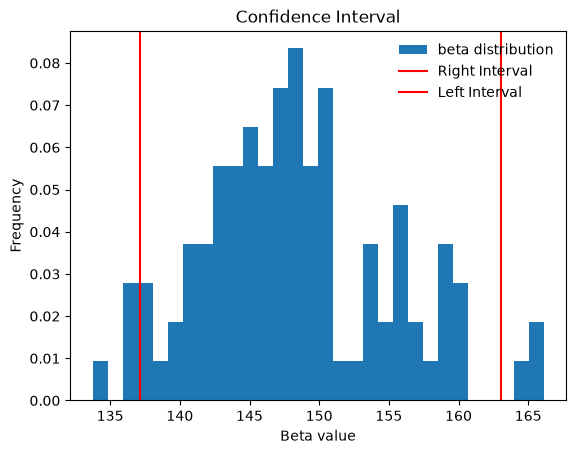

In [10]:
# Call the function plot_simulation to get the histogram for beta 0
# with the confidence interval
plot_simulation(beta0_list, beta0_CI)


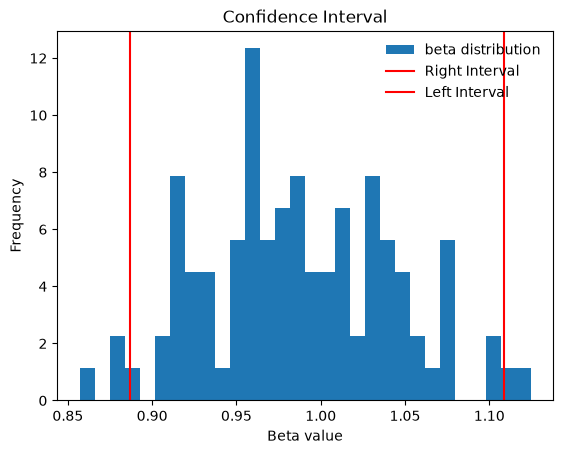

In [11]:
# Call the function plot_simulation to get the histogram for beta 1
# with the confidence interval
plot_simulation(beta1_list, beta1_CI)
